# Сравнение алгоритмов в лабораторных работах 1–5

**Коробейников Даниил Андреевич · М8О-406Б-23 · МАИ**

Сравниваем пять семейств моделей на одном разбиении для каждой задачи. Для основного выбора используем кросс-валидацию на train. Тестовые метрики, сравнения реализаций и диагностика показывают, что получилось на отложенных объектах. Исходный расчёт описан в [ноутбуке с лабораторными](01_labs_1_5.ipynb).

In [1]:
# Загружаем результаты пяти работ и задаём подписи в порядке лабораторных.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = "{:.4f}".format
results_dir = Path("results")
metrics = pd.read_csv(results_dir / "metrics.csv")
predictions = pd.read_csv(results_dir / "predictions.csv")
labels = {1: "KNN", 2: "Линейные модели", 3: "Дерево", 4: "Случайный лес", 5: "Бустинг"}
versions = ["sklearn · база", "sklearn · подбор", "Своя · база", "Своя · перенос"]
metrics["Метод"] = metrics["lab"].map(labels)
metrics["variant"] = pd.Categorical(metrics["variant"], categories=versions, ordered=True)
assert len(metrics) == 40 and not metrics.duplicated(["lab", "task", "variant"]).any()

## Тестовые метрики всех 40 моделей

F1-macro и Accuracy сравниваем для Sonar, MAE, RMSE и R² — для Concrete Slump Test.

In [2]:
# Показываем 20 конфигураций на каждую задачу и все выбранные метрики.
for task, title, columns in [
    ("classification", "Sonar · классификация", ["F1_macro", "Accuracy"]),
    ("regression", "Concrete Slump Test · регрессия", ["MAE", "RMSE", "R2"]),
]:
    group = metrics.loc[metrics["task"] == task].sort_values(["lab", "variant"])
    display(Markdown(f"### {title}"))
    display(group.set_index(["Метод", "variant"])[columns].rename_axis(index=["Метод", "Версия"]))

### Sonar · классификация

F1_macro  Accuracy
Метод           Версия                              
KNN             sklearn · база      0.8325    0.8333
                sklearn · подбор    0.8803    0.8810
                Своя · база         0.8325    0.8333
                Своя · перенос      0.8803    0.8810
Линейные модели sklearn · база      0.8078    0.8095
                sklearn · подбор    0.8568    0.8571
                Своя · база         0.8078    0.8095
                Своя · перенос      0.8568    0.8571
Дерево          sklearn · база      0.8286    0.8333
                sklearn · подбор    0.7379    0.7381
                Своя · база         0.7856    0.7857
                Своя · перенос      0.8095    0.8095
Случайный лес   sklearn · база      0.8078    0.8095
                sklearn · подбор    0.8558    0.8571
                Своя · база         0.8056    0.8095
                Своя · перенос      0.8091    0.8095
Бустинг         sklearn · база      0.8568    0.8571
                sklearn · подбор    0.8568    0.8571
                Своя · база         0.8568    0.8571
                Своя · перенос      0.8568    0.8571

### Concrete Slump Test · регрессия

MAE   RMSE     R2
Метод           Версия                               
KNN             sklearn · база   2.5214 2.9358 0.8297
                sklearn · подбор 2.1758 2.4733 0.8791
                Своя · база      2.5214 2.9358 0.8297
                Своя · перенос   2.1758 2.4733 0.8791
Линейные модели sklearn · база   1.7310 2.0685 0.9154
                sklearn · подбор 1.7301 2.0653 0.9157
                Своя · база      1.7310 2.0685 0.9154
                Своя · перенос   1.7301 2.0653 0.9157
Дерево          sklearn · база   2.9905 4.2153 0.6488
                sklearn · подбор 2.9547 3.4316 0.7673
                Своя · база      3.5567 4.5507 0.5907
                Своя · перенос   2.9380 3.4530 0.7644
Случайный лес   sklearn · база   2.5684 3.2853 0.7867
                sklearn · подбор 1.9889 2.4086 0.8853
                Своя · база      2.3209 2.8171 0.8431
                Своя · перенос   2.0377 2.3542 0.8905
Бустинг         sklearn · база   2.2842 2.9035 0.8334
                sklearn · подбор 1.6226 1.9871 0.9220
                Своя · база      2.3294 2.9594 0.8269
                Своя · перенос   1.6349 2.0017 0.9208

## Сравнение исходных и настроенных вариантов

Движение вправо означает увеличение метрики. Для F1-macro это улучшение, для MAE — рост ошибки.

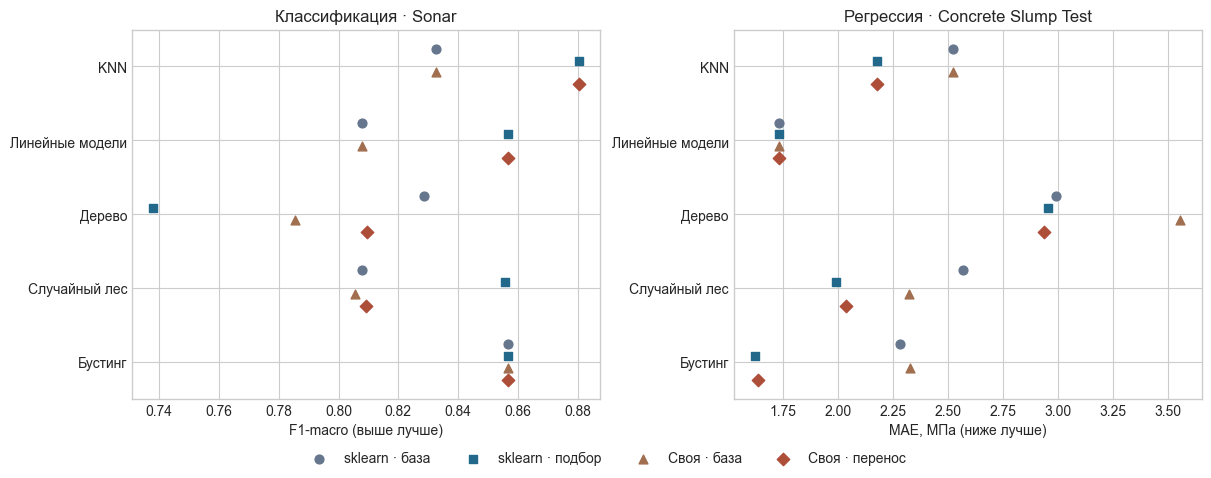

In [3]:
# Сравниваем четыре версии каждого метода на одной шкале внутри каждой задачи.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout="constrained")
markers = ["o", "s", "^", "D"]
colors = ["#65768d", "#21688b", "#a16f4f", "#ad4e39"]
offsets = [-0.24, -0.08, 0.08, 0.24]
for ax, task, key, title, xlabel in [
    (axes[0], "classification", "F1_macro", "Классификация · Sonar", "F1-macro (выше лучше)"),
    (axes[1], "regression", "MAE", "Регрессия · Concrete Slump Test", "MAE, МПа (ниже лучше)"),
]:
    group = metrics.loc[metrics["task"] == task]
    for version, marker, color, offset in zip(versions, markers, colors, offsets):
        scores = group.loc[group["variant"] == version].sort_values("lab")
        ax.scatter(scores[key], np.arange(len(labels)) + offset,
                   marker=marker, color=color, s=40, label=version, zorder=3)
    ax.set(yticks=np.arange(len(labels)), yticklabels=list(labels.values()),
           title=title, xlabel=xlabel)
    ax.set_ylim(len(labels) - 0.5, -0.5)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside lower center", ncols=4, frameon=False)
plt.show()

## Модели по результатам кросс-валидации

Для диагностики выбираем по одной настроенной модели sklearn на задачу. Критерий выбора — средний F1-macro или MAE на CV. Графики и таблица ниже построены на тестовой выборке.

,Sonar · Метод,Sonar · CV F1-macro,Бетон · Метод,"Бетон · CV MAE, МПа"
0,KNN,0.8476,Бустинг,1.6973
1,Бустинг,0.8407,Линейные модели,2.2852
2,Линейные модели,0.8291,Случайный лес,2.3676
3,Случайный лес,0.7990,KNN,2.4060
4,Дерево,0.7496,Дерево,2.4999


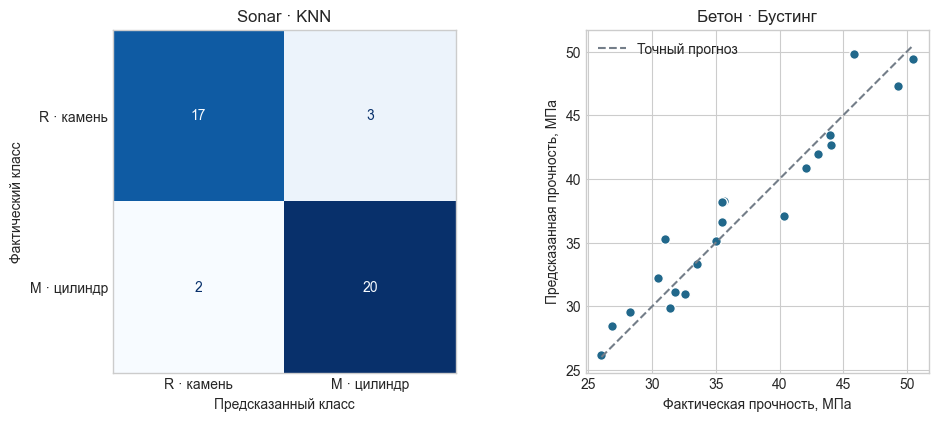

In [4]:
# Выбираем лидеров по CV и проверяем характер их ошибок на тесте.
tuned = metrics.loc[metrics["variant"] == "sklearn · подбор"]
clf_tuned = tuned.loc[tuned["task"] == "classification"].sort_values("CV", ascending=False)
reg_tuned = tuned.loc[tuned["task"] == "regression"].sort_values("CV")
best_clf, best_reg = clf_tuned.iloc[0], reg_tuned.iloc[0]
cv_view = pd.concat([clf_tuned[["Метод", "CV"]].reset_index(drop=True).add_prefix("Sonar · "),
                     reg_tuned[["Метод", "CV"]].reset_index(drop=True).add_prefix("Бетон · ")], axis=1)
display(cv_view.rename(columns={"Sonar · CV": "Sonar · CV F1-macro",
                                "Бетон · CV": "Бетон · CV MAE, МПа"}))

clf_pred = predictions[(predictions["task"] == "classification") &
                       (predictions["lab"] == best_clf["lab"]) &
                       (predictions["variant"] == "sklearn · подбор")]
reg_pred = predictions[(predictions["task"] == "regression") &
                       (predictions["lab"] == best_reg["lab"]) &
                       (predictions["variant"] == "sklearn · подбор")]
confusion = confusion_matrix(clf_pred["actual"], clf_pred["predicted"], labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.1), layout="constrained")
ConfusionMatrixDisplay(confusion, display_labels=["R · камень", "M · цилиндр"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].grid(False)
axes[0].set(title=f"Sonar · {best_clf['Метод']}", xlabel="Предсказанный класс",
            ylabel="Фактический класс")
actual, predicted = reg_pred["actual"], reg_pred["predicted"]
low, high = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
axes[1].scatter(actual, predicted, color="#21688b", edgecolor="white", s=49)
axes[1].plot([low, high], [low, high], linestyle="--", color="#747e89", label="Точный прогноз")
axes[1].set(title=f"Бетон · {best_reg['Метод']}", xlabel="Фактическая прочность, МПа",
            ylabel="Предсказанная прочность, МПа")
axes[1].set_aspect("equal", adjustable="box")
axes[1].legend(frameon=False)
plt.show()

## Выводы и ограничения

In [5]:
# Формируем выводы по фактически полученным метрикам, включая случаи ухудшения.
notes = []
for task, key, leader, direction, units in [
    ("classification", "F1_macro", best_clf, 1, ""),
    ("regression", "MAE", best_reg, -1, " МПа"),
]:
    group = metrics.loc[metrics["task"] == task]
    wide = group.pivot(index="lab", columns="variant", values=key)
    sklearn_delta = direction * (wide["sklearn · подбор"] - wide["sklearn · база"])
    own_delta = direction * (wide["Своя · перенос"] - wide["Своя · база"])
    best_test = group.iloc[np.argmax(direction * group[key].to_numpy())]
    notes.append(
        f"- **{key}.** По CV выбран метод «{leader['Метод']}». CV = {leader['CV']:.4f}{units}, "
        f"test = {leader[key]:.4f}{units}. Лучшее наблюдаемое значение на test — "
        f"{best_test[key]:.4f}{units} у «{best_test['Метод']}» ({best_test['variant']}). "
        f"Настройка улучшила тестовый результат sklearn в {(sklearn_delta > 1e-9).sum()} из 5 работ. "
        f"Перенос настроек улучшил свою модель в {(own_delta > 1e-9).sum()} из 5."
    )

notes.append(
    f"- Sonar. Выбранная модель перепутала {confusion[0, 1]} записей с камнем и "
    f"{confusion[1, 0]} записей с цилиндром. Бетон. На графике прочности "
    "расстояние по вертикали до диагонали равно абсолютной ошибке по смеси."
)
notes.append(
    "- На test всего 42 сигнала и 21 смесь. Различия в несколько предсказаний заметно меняют "
    "метрики. CV использовалась для подбора, поэтому её лидерство служит критерием выбора, "
    "а устойчивость вывода требует новых записей или независимых повторов эксперимента."
)
display(Markdown("\n".join(notes)))

- **F1_macro.** По CV выбран метод «KNN». CV = 0.8476, test = 0.8803. Лучшее наблюдаемое значение на test — 0.8803 у «KNN» (sklearn · подбор). Настройка улучшила тестовый результат sklearn в 3 из 5 работ. Перенос настроек улучшил свою модель в 4 из 5.
- **MAE.** По CV выбран метод «Бустинг». CV = 1.6973 МПа, test = 1.6226 МПа. Лучшее наблюдаемое значение на test — 1.6226 МПа у «Бустинг» (sklearn · подбор). Настройка улучшила тестовый результат sklearn в 5 из 5 работ. Перенос настроек улучшил свою модель в 5 из 5.
- Sonar. Выбранная модель перепутала 3 записей с камнем и 2 записей с цилиндром. Бетон. На графике прочности расстояние по вертикали до диагонали равно абсолютной ошибке по смеси.
- На test всего 42 сигнала и 21 смесь. Различия в несколько предсказаний заметно меняют метрики. CV использовалась для подбора, поэтому её лидерство служит критерием выбора, а устойчивость вывода требует новых записей или независимых повторов эксперимента.